In [1]:
import pandas as pd, joblib
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

log_model = joblib.load("log_model.pkl")
tree_model = joblib.load("tree_model.pkl")
rf_model = joblib.load("rf_model.pkl")
preds = pd.read_csv("test_predictions.csv")
preds.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,actual,logistic_pred,tree_pred,forest_pred
0,0,59,75.95,4542.35,False,True,True,True,False,False,...,False,True,True,True,False,False,0,0,0,0
1,0,7,78.55,522.95,False,False,False,True,False,True,...,False,False,True,False,False,False,0,1,1,1
2,0,54,20.10,1079.45,False,False,False,True,False,False,...,False,True,False,False,False,True,0,0,0,0
3,0,2,20.65,38.70,False,False,False,True,False,False,...,False,False,False,False,False,True,1,0,0,0
4,0,71,105.15,7555.00,False,True,False,True,False,True,...,False,True,True,False,False,False,0,0,0,0


In [2]:
import sklearn
print(sklearn.__version__)

1.9.1


In [3]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             accuracy_score, ConfusionMatrixDisplay)

df = pd.read_csv("test_predictions.csv")
y_true = df["actual"]
pred_cols = {"Logistic regression": "logistic_pred",
             "Decision tree": "tree_pred",
             "Random forest": "forest_pred"}
X_test = df.drop(columns=["actual", *pred_cols.values()])

In [ ]:
rows = []
for name, col in pred_cols.items():
    p = df[col]
    rows.append({"Model": name,
                 "Precision (churn)": precision_score(y_true, p),
                 "Recall (churn)": recall_score(y_true, p),5
                 "F1 (churn)": f1_score(y_true, p),
                 "Accuracy": accuracy_score(y_true, p)})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Precision (churn),Recall (churn),F1 (churn),Accuracy
Model,,,,
Logistic regression,0.491,0.797,0.608,0.726
Decision tree,0.468,0.783,0.586,0.706
Random forest,0.560,0.660,0.606,0.772


Logistic regression has the highest F1 (0.608, level with the random forest's 0.606) and the highest recall (0.797), so it catches the most customers who actually leave, 298 of 374. It is also the easiest model to explain, because each feature has a single coefficient showing whether it raises or lowers churn risk

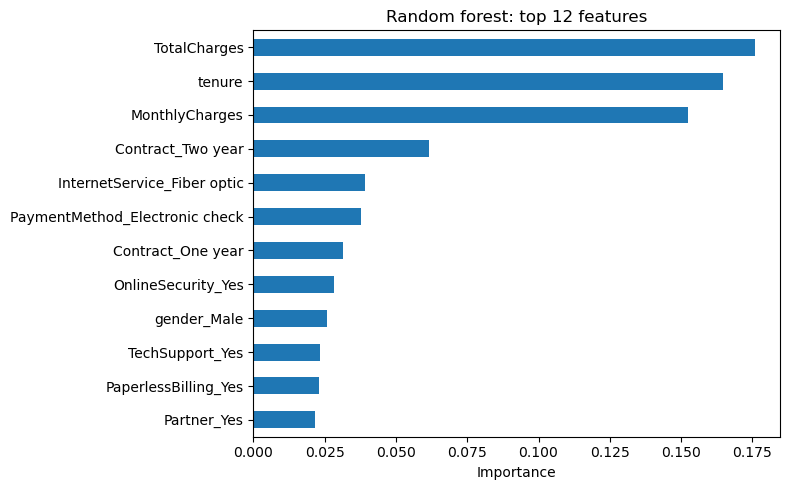

In [21]:
rf_model = joblib.load("rf_model.pkl")
log_model = joblib.load("log_model.pkl")

# sanity check: the columns must match what the models were trained on
assert list(rf_model.feature_names_in_) == list(X_test.columns)

imp = pd.Series(rf_model.feature_importances_, index=X_test.columns).sort_values()
imp.tail(12).plot(kind="barh", figsize=(8, 5), title="Random forest: top 12 features")
plt.xlabel("Importance"); plt.tight_layout();
plt.savefig("feature_importance_rf.png", dpi=150, bbox_inches="tight")
plt.show()

# direction of effect (positive = more likely to churn)
coefs = pd.Series(log_model[-1].coef_[0], index=X_test.columns).sort_values()


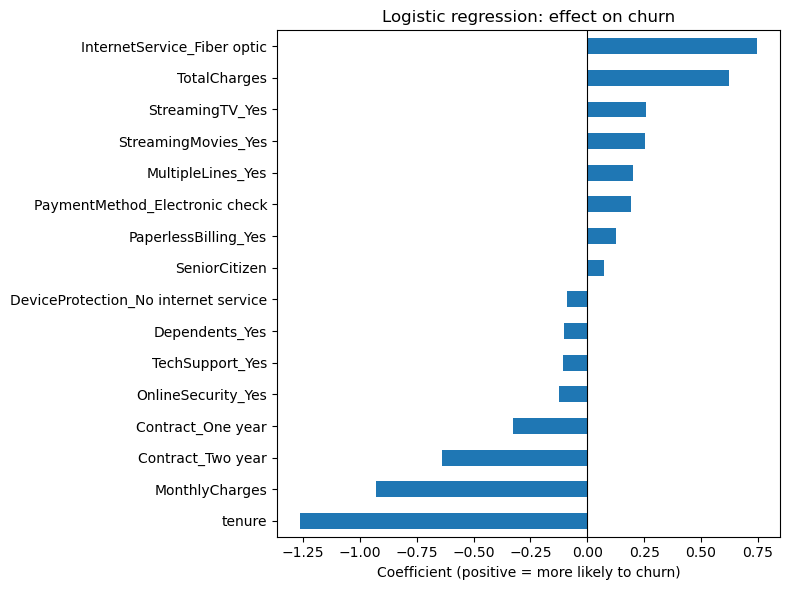

In [20]:
top = pd.concat([coefs.head(8), coefs.tail(8)])   # 8 most negative, 8 most positive
top.plot(kind="barh", figsize=(8, 6), title="Logistic regression: effect on churn")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient (positive = more likely to churn)")
plt.tight_layout();
plt.savefig("feature_importance_lr.png", dpi=150, bbox_inches="tight");  plt.show()

In [18]:
clean = pd.read_csv("telco_clean.csv")
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print((clean.groupby(col)["Churn"].mean() * 100).round(1), "\n")

clean["tenure_group"] = pd.cut(clean["tenure"], [0, 12, 24, 48, 72])
print((clean.groupby("tenure_group")["Churn"].mean() * 100).round(1))

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.3
Electronic check             45.3
Mailed check                 19.2
Name: Churn, dtype: float64 

tenure_group
(0, 12]     47.7
(12, 24]    28.7
(24, 48]    20.4
(48, 72]     9.5
Name: Churn, dtype: float64


C:\Users\Hp\AppData\Local\Temp\ipykernel_17660\3233418103.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print((clean.groupby("tenure_group")["Churn"].mean() * 100).round(1))


Recommendations

Contract: month-to-month customers churn at 42.7% against 2.8% on two-year contracts. Offer discounts or perks to move month-to-month customers onto annual or two-year plans.

Early tenure: customers in their first year churn at 47.7%, against 9.5% after four years. Add onboarding support or a welcome offer during the first 12 months.

Fiber optic: 41.9% churn, more than double DSL. Investigate service quality, pricing or competition for fiber customers. Be careful with wording, because this shows an association, not proof that fiber causes churn.

Payment method: electronic check users churn at 45.3%, against about 15% for automatic payments. Encourage a switch to automatic payment, for example with a small bill credit.